# Homework 2
Karl Rummler

## Problem 2a

In [1]:
import pandas as pd
%config InlineBackend.figure_format = 'retina'

In [2]:
df = pd.read_csv('retail.csv')
cols = ['StockCode', 'CustomerID']
df[cols] = df[cols].astype('category')

In [3]:
len(df)

397924

In [4]:
df.head()

,Quantity,StockCode,CustomerID
0,6,85123A,17850.0
1,6,71053,17850.0
2,8,84406B,17850.0
3,6,84029G,17850.0
4,6,84029E,17850.0


<Axes: >

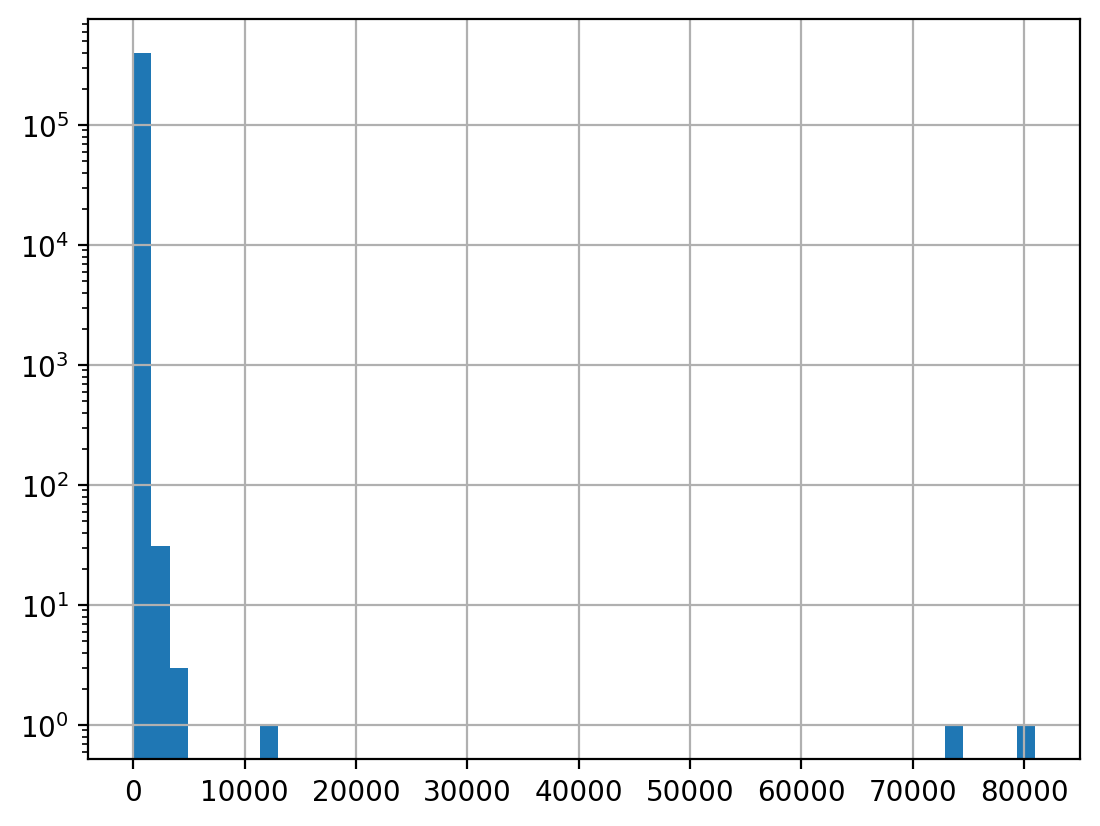

In [5]:
df['Quantity'].hist(bins=50, log=True)

### Part (a)

In [6]:
stock_code_nunique = df['StockCode'].nunique()
customer_id_nunique = df['CustomerID'].nunique()
print('Unique StockCode count: ', stock_code_nunique)
print('Unique CustomerID count: ', customer_id_nunique)

Unique StockCode count:  3665
Unique CustomerID count:  4339


In [7]:
from sklearn.model_selection import train_test_split

# 80% train, 20% temporary holdout
train_df, temp_df = train_test_split(df, test_size=0.2, random_state=42)
# Split the 20% holdout equally into 10% validation and 10% test
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

In [8]:
# Check size
(len(train_df)+len(val_df)+len(test_df))==len(df)

True

### Part (b)

In [9]:
!pip install category-encoders

In [10]:
from category_encoders import TargetEncoder
cols=['StockCode', 'CustomerID']
encoder = TargetEncoder(cols=cols)

# Encode the input features such that they will take on the average
# of the training label across keyed by the input feature value
# Don't use validation set because model's training data will be different
X_encoded_train = encoder.fit_transform(
    X=(train_df)[cols],
    y=(train_df)['Quantity']
)
X_encoded_test = encoder.transform(test_df[cols])

In [11]:
# Snippet of the encoded data
X_encoded_train.head()

,StockCode,CustomerID
36226,11.076097,13.769893
142837,2.555556,92.271238
381442,3.248272,13.902564
186343,16.077872,14.000000
148247,6.667910,11.676522


In [12]:
# HuberRegresor Penalizes small errors quadratically
# and large errors approximately linear

from sklearn.linear_model import HuberRegressor
model = HuberRegressor(alpha=0)
model.fit(X_encoded_train, train_df['Quantity'])

HuberRegressor(alpha=0)

In [13]:
test_predictions = model.predict(X_encoded_test)

In [14]:
def mse(y_true, y_pred):
  return ((y_true-y_pred)**2).mean()

In [15]:
test_mse = mse(test_df['Quantity'], test_predictions)
baseline_mse = mse(test_df['Quantity'], train_df['Quantity'].mean())

print('Baseline Mean Prediction: Test MSE: %0.2f'% baseline_mse)
print('HuberRegressor + Encoding: Test MSE: %0.2f'% test_mse)

Baseline Mean Prediction: Test MSE: 2089.32
HuberRegressor + Encoding: Test MSE: 1512.71


### Part (C)

In [16]:
import torch
from torch import nn

1. Categorical feature to embedding row number map

In [17]:
stock_to_id = {
    stock: i + 1
    for i, stock in enumerate(train_df['StockCode'].unique())
}

list(stock_to_id.items())[:5]

[('47566', 1), ('22846', 2), ('22781', 3), ('20832', 4), ('21907', 5)]

In [18]:
customer_to_id = {
    customer: i + 1
    for i, customer in enumerate(train_df['CustomerID'].unique())
}

list(customer_to_id.items())[:5]

[(12388.0, 1), (14646.0, 2), (13599.0, 3), (17593.0, 4), (17675.0, 5)]

2. Tensor of the training data categorical features mapped to their respective ids

In [19]:
stock_train = torch.tensor(
    train_df['StockCode'].map(stock_to_id).to_numpy(),
    dtype=torch.long
)

customer_train = torch.tensor(
    train_df['CustomerID'].map(customer_to_id).to_numpy(),
    dtype=torch.long
)

In [20]:
stock_train[:5], customer_train[:5]

(tensor([1, 2, 3, 4, 5]), tensor([1, 2, 3, 4, 5]))

3. Creating embedding $n\times8$

In [21]:
stock_embedding = nn.Embedding(
    # Add 1 for a reserved row
    len(stock_to_id) + 1, 8, padding_idx=0
)

customer_embedding = nn.Embedding(
    len(customer_to_id) + 1, 8, padding_idx=0
)

In [22]:
stock_embedding(stock_train).shape

torch.Size([318339, 8])

4. Concat the two embeddings side by side

In [23]:
stock_vectors = stock_embedding(stock_train[:5])
customer_vectors = customer_embedding(customer_train[:5])

# Dim 1 joins by side, dim 0 stacks
combined = torch.cat([stock_vectors, customer_vectors], dim=1)

combined.shape

torch.Size([5, 16])

In [24]:
prediction_net = nn.Sequential(
    # 16 to match the 8 + 8 from embedding size
    nn.Linear(16, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)
predictions = prediction_net(combined)

predictions.shape

torch.Size([5, 1])

5. Use embedded inputs to predict quantity

In [25]:
y_train = torch.tensor(
    train_df['Quantity'].to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)
# Reshapes into a matrix, -1 means empty for that dimension

loss_fn = nn.HuberLoss()
loss = loss_fn(predictions, y_train[:5])

loss.item()

11.706692695617676

6. do a training update

In [26]:
# gather all the tensors so the optimizer can update them
# includes embeddings
# neural network layers (Linear, ReLu, Linear)
parameters = (
    # parameter returns iterator so it can be made a list
    list(stock_embedding.parameters())
    # + means join
    + list(customer_embedding.parameters())
    + list(prediction_net.parameters())
)

optimizer = torch.optim.Adam(parameters, lr=0.001)

7. Prepare batches for training on full dataset

In [27]:
train_dataset = torch.utils.data.TensorDataset(
    stock_train, # mapped Ids
    customer_train, # mapped Ids
    y_train
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)

8. Do one epoch training run for sanity check

In [28]:

for epoch in range(1):
  total_loss = 0.0

  for stock_ids, customer_ids, quantities in train_loader:
    batch_size = len(quantities)

    # Clear out the old gradients
    optimizer.zero_grad()

    # stock_id -> embeddings vectors
    stock_vectors = stock_embedding(stock_ids)
    customer_vectors = customer_embedding(customer_ids)

    # Column join everything
    features = torch.cat([stock_vectors, customer_vectors], dim=1)

    # predict and calculate loss
    predictions = prediction_net(features)
    loss = loss_fn(predictions, quantities)

    #
    loss.backward()
    optimizer.step()

    # loss.item is teh average loss for that batch.
    total_loss += loss.item() * batch_size

print('Training Huber loss:', total_loss / len(train_dataset))

Training Huber loss: 11.024527123524729


9. prepare validation data with same mappings

In [29]:
stock_val = torch.tensor(
    val_df['StockCode'].astype(object).map(stock_to_id).fillna(0).to_numpy(),
    dtype=torch.long
)

customer_val = torch.tensor(
    # fill na is here in case we see a new category, hence has no map
    # hence goes to the default 0 row from adding before
    val_df['CustomerID'].astype(object).map(customer_to_id).fillna(0).to_numpy(),
    dtype=torch.long
)

y_val = torch.tensor(
    val_df['Quantity'].to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

val_loader = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(stock_val, customer_val, y_val),
    batch_size=1024,
    shuffle=False
)

10. evaluate on validation set

In [30]:
import copy

modules = (stock_embedding, customer_embedding, prediction_net)
best_val = float('inf')
best_states = [copy.deepcopy(m.state_dict()) for m in modules]
patience = 5
wait = 0

for epoch in range(30):
    # set to training mode
    for m in modules:
        m.train()

    for stock_ids, customer_ids, quantities in train_loader:
        optimizer.zero_grad()

        features = torch.cat([
            stock_embedding(stock_ids),
            customer_embedding(customer_ids)
        ], dim=1)

        predictions = prediction_net(features)
        loss = loss_fn(predictions, quantities)
        loss.backward()
        optimizer.step()

    # set to eval mode
    for m in modules:
        m.eval()


    # calc val loss
    val_total_loss = 0.0
    with torch.no_grad():
        for stock_ids, customer_ids, quantities in val_loader:
            features = torch.cat([
                stock_embedding(stock_ids),
                customer_embedding(customer_ids)
            ], dim=1)

            predictions = prediction_net(features)
            loss = loss_fn(predictions, quantities)
            val_total_loss += loss.item() * len(quantities)

    val_loss = val_total_loss / len(val_loader.dataset)
    print(f'Epoch {epoch + 1}: validation loss = {val_loss:.4f}')

    # cmp with best validation loss
    if val_loss < best_val:
        best_val = val_loss
        best_states = [copy.deepcopy(m.state_dict()) for m in modules]
        wait = 0
    else:
        wait += 1

    # If haven't improved on validation set in 5 epochs stop.
    # Perhaps X% better than.
    if wait >= patience:
        break

for m, state in zip(modules, best_states):
    m.load_state_dict(state)

Epoch 1: validation loss = 8.6585
Epoch 2: validation loss = 7.9717
Epoch 3: validation loss = 7.3295
Epoch 4: validation loss = 6.8505
Epoch 5: validation loss = 6.5191
Epoch 6: validation loss = 6.2915
Epoch 7: validation loss = 6.1312
Epoch 8: validation loss = 6.0092
Epoch 9: validation loss = 5.9203
Epoch 10: validation loss = 5.8460
Epoch 11: validation loss = 5.7831
Epoch 12: validation loss = 5.7304
Epoch 13: validation loss = 5.6846
Epoch 14: validation loss = 5.6460
Epoch 15: validation loss = 5.6076
Epoch 16: validation loss = 5.5750
Epoch 17: validation loss = 5.5459
Epoch 18: validation loss = 5.5193
Epoch 19: validation loss = 5.4954
Epoch 20: validation loss = 5.4715
Epoch 21: validation loss = 5.4487
Epoch 22: validation loss = 5.4275
Epoch 23: validation loss = 5.4078
Epoch 24: validation loss = 5.3912
Epoch 25: validation loss = 5.3768
Epoch 26: validation loss = 5.3630
Epoch 27: validation loss = 5.3472
Epoch 28: validation loss = 5.3333
Epoch 29: validation loss = 5

11. eval on test set

In [31]:
# map them to ids
stock_test = torch.tensor(
    test_df['StockCode'].astype(object).map(stock_to_id).fillna(0).to_numpy(),
    dtype=torch.long
)

customer_test = torch.tensor(
    test_df['CustomerID'].astype(object).map(customer_to_id).fillna(0).to_numpy(),
    dtype=torch.long
)

stock_embedding.eval()
customer_embedding.eval()
prediction_net.eval()

with torch.no_grad():
    features = torch.cat([
        stock_embedding(stock_test),
        customer_embedding(customer_test)
    ], dim=1)

    nn_test_predictions = prediction_net(features).squeeze(1).numpy()

nn_test_mse = mse(test_df['Quantity'].to_numpy(), nn_test_predictions)

print('Part (b) test MSE:', test_mse)
print('Part (c) test MSE:', nn_test_mse)

Part (b) test MSE: 1512.7130131697127
Part (c) test MSE: 1538.6377794619182


### Part (d)

In [32]:
encoder_d = TargetEncoder(cols=cols)

encoded_train_d = encoder_d.fit_transform(
    train_df[cols],
    train_df['Quantity']
)

encoded_test_d = encoder_d.transform(test_df[cols])

encoded_train_d.head()

,StockCode,CustomerID
36226,11.076097,13.769893
142837,2.555556,92.271238
381442,3.248272,13.902564
186343,16.077872,14.000000
148247,6.667910,11.676522


In [33]:
from sklearn.preprocessing import StandardScaler

scaler_d = StandardScaler()

encoded_train_tensor_d = torch.tensor(
    scaler_d.fit_transform(encoded_train_d),
    dtype=torch.float32
)

encoded_test_tensor_d = torch.tensor(
    scaler_d.transform(encoded_test_d),
    dtype=torch.float32
)

encoded_train_tensor_d.shape

torch.Size([318339, 2])

In [34]:
stock_embedding_d = nn.Embedding(
    len(stock_to_id) + 1, 8, padding_idx=0
)

customer_embedding_d = nn.Embedding(
    len(customer_to_id) + 1, 8, padding_idx=0
)

prediction_net_d = nn.Sequential(
    nn.Linear(18, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

combined_d = torch.cat([
    stock_embedding_d(stock_train[:5]),
    customer_embedding_d(customer_train[:5]),
    encoded_train_tensor_d[:5]
], dim=1)

combined_d.shape

torch.Size([5, 18])

In [35]:
train_dataset_d = torch.utils.data.TensorDataset(
    stock_train,
    customer_train,
    encoded_train_tensor_d,
    y_train
)

train_loader_d = torch.utils.data.DataLoader(
    train_dataset_d,
    batch_size=1024,
    shuffle=True
)

new optimizer

In [36]:
parameters_d = (
    list(stock_embedding_d.parameters())
    + list(customer_embedding_d.parameters())
    + list(prediction_net_d.parameters())
)

optimizer_d = torch.optim.Adam(parameters_d, lr=0.001)

validation loader

In [37]:
encoded_val_d = encoder_d.transform(val_df[cols])

encoded_val_tensor_d = torch.tensor(
    scaler_d.transform(encoded_val_d),
    dtype=torch.float32
)

val_loader_d = torch.utils.data.DataLoader(
    torch.utils.data.TensorDataset(
        stock_val,
        customer_val,
        encoded_val_tensor_d,
        y_val
    ),
    batch_size=1024,
    shuffle=False
)

train with validation early stopping


In [38]:
import copy

modules_d = (stock_embedding_d, customer_embedding_d, prediction_net_d)
patience = 5
wait_d = 0
best_val_d = float('inf')
best_states_d = [copy.deepcopy(m.state_dict()) for m in modules_d]

for epoch in range(40):
    for m in modules_d:
        m.train()

    train_total_loss_d = 0.0

    for stock_ids, customer_ids, encoded_values, quantities in train_loader_d:
        optimizer_d.zero_grad()

        features = torch.cat([
            stock_embedding_d(stock_ids),
            customer_embedding_d(customer_ids),
            encoded_values
        ], dim=1)

        predictions = prediction_net_d(features)
        loss = loss_fn(predictions, quantities)

        loss.backward()
        optimizer_d.step()

        train_total_loss_d += loss.item() * len(quantities)

    train_loss_d = train_total_loss_d / len(train_dataset_d)

    for m in modules_d:
        m.eval()

    val_total_loss_d = 0.0

    with torch.no_grad():
        for stock_ids, customer_ids, encoded_values, quantities in val_loader_d:
            features = torch.cat([
                stock_embedding_d(stock_ids),
                customer_embedding_d(customer_ids),
                encoded_values
            ], dim=1)

            predictions = prediction_net_d(features)
            loss = loss_fn(predictions, quantities)

            val_total_loss_d += loss.item() * len(quantities)

    val_loss_d = val_total_loss_d / len(val_loader_d.dataset)

    print(
        f'Epoch {epoch + 1}: '
        f'training Huber loss = {train_loss_d:.4f}, '
        f'validation Huber loss = {val_loss_d:.4f}'
    )

    if val_loss_d < best_val_d:
        best_val_d = val_loss_d
        best_states_d = [copy.deepcopy(m.state_dict()) for m in modules_d]
        wait_d = 0
    else:
        wait_d += 1

    if wait_d >= patience:
        print('Early stopping')
        break

for m, state in zip(modules_d, best_states_d):
    m.load_state_dict(state)

Epoch 1: training Huber loss = 11.1397, validation Huber loss = 9.0031
Epoch 2: training Huber loss = 9.0564, validation Huber loss = 7.5903
Epoch 3: training Huber loss = 7.8629, validation Huber loss = 6.8992
Epoch 4: training Huber loss = 7.4528, validation Huber loss = 6.6811
Epoch 5: training Huber loss = 7.2553, validation Huber loss = 6.5103
Epoch 6: training Huber loss = 7.0832, validation Huber loss = 6.3558
Epoch 7: training Huber loss = 6.9349, validation Huber loss = 6.2257
Epoch 8: training Huber loss = 6.8106, validation Huber loss = 6.1170
Epoch 9: training Huber loss = 6.7049, validation Huber loss = 6.0215
Epoch 10: training Huber loss = 6.6097, validation Huber loss = 5.9371
Epoch 11: training Huber loss = 6.5231, validation Huber loss = 5.8576
Epoch 12: training Huber loss = 6.4445, validation Huber loss = 5.7865
Epoch 13: training Huber loss = 6.3724, validation Huber loss = 5.7208
Epoch 14: training Huber loss = 6.3049, validation Huber loss = 5.6561
Epoch 15: trai

In [39]:
stock_embedding_d.eval()
customer_embedding_d.eval()
prediction_net_d.eval()

with torch.no_grad():
    features = torch.cat([
        stock_embedding_d(stock_test),
        customer_embedding_d(customer_test),
        encoded_test_tensor_d
    ], dim=1)

    test_predictions_d = prediction_net_d(features).squeeze(1).numpy()

test_mse_d = mse(test_df['Quantity'].to_numpy(), test_predictions_d)

print('Part (b) test MSE:', test_mse)
print('Part (c) test MSE:', nn_test_mse)
print('Part (d) test MSE:', test_mse_d)

Part (b) test MSE: 1512.7130131697127
Part (c) test MSE: 1538.6377794619182
Part (d) test MSE: 1337.8757105497725
